In [ ]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
from sklearn.model_selection import train_test_split

In [ ]:
# Load the CSV file into a DataFrame
data = pd.read_csv('/content/churn_data.csv')

# Display the first few rows of the DataFrame
data.head()

,RowNumber,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,IsActiveMember,EstimatedSalary,Exited
0,0,619,0,0,42,2,0.00,1,1,101348.88,1
1,1,608,2,0,41,1,83807.86,1,1,112542.58,0
2,2,502,0,0,42,8,159660.80,3,0,113931.57,1
3,3,699,0,0,39,1,0.00,2,0,93826.63,0
4,4,850,2,0,43,2,125510.82,1,1,79084.10,0


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CreditScore      10000 non-null  int64  
 2   Geography        10000 non-null  int64  
 3   Gender           10000 non-null  int64  
 4   Age              10000 non-null  int64  
 5   Tenure           10000 non-null  int64  
 6   Balance          10000 non-null  float64
 7   NumOfProducts    10000 non-null  int64  
 8   IsActiveMember   10000 non-null  int64  
 9   EstimatedSalary  10000 non-null  float64
 10  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9)
memory usage: 859.5 KB


In [ ]:
data.shape

(10000, 11)

In [ ]:
data.nunique()

RowNumber          10000
CreditScore          460
Geography              3
Gender                 2
Age                   70
Tenure                11
Balance             6382
NumOfProducts          4
IsActiveMember         2
EstimatedSalary     9999
Exited                 2
dtype: int64

In [ ]:
# Separate dataframe into separate objects

# Object for input features
x = data.loc[:,["CreditScore","Tenure","Balance","NumOfProducts","IsActiveMember","EstimatedSalary"]].values

# Object for target variable
y = data.iloc[:,-1]

In [ ]:
print(x.shape)
print(y.shape)

(10000, 6)
(10000,)


In [ ]:
def class_count(data):
    counter = Counter(data)
    kv = [list(counter.keys()), list(counter.values())]
    data2 = pd.DataFrame(np.array(kv).T, columns=['Exited', 'Count'])
    data2['Count'] = data2['Count'].astype('int64')
    data2['%'] = round(data2['Count'] / data.shape[0] * 100, 2)
    return data2.sort_values('Count', ascending=False)

print(class_count(y))

   Exited  Count      %
1       0   7963  79.63
0       1   2037  20.37


In [ ]:
# Spliting it into training and testing sets.
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 1)

In [ ]:
# Print number of observations in X_train, X_test, y_train, and y_test

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(8000, 6)
(2000, 6)
(8000,)
(2000,)


In [ ]:
# KNN model class

class KNN:
    def __init__(self):
        self.neighbors = 1

    def euclidean_distance(self, x1, y1, x2, y2):
        return math.sqrt((x2 - x1)**2 + (y2 - y1)**2)

    def fit(self, X_train, Y_train):
        self.X_train = X_train
        self.Y_train = Y_train

    def sort_on_float(self, sublist):
        return [a for a in sublist if isinstance(a, float)]

    def predict(self, X_test):
        n_neighbors = 5
        X_train = self.X_train
        Y_train = self.Y_train
        result = []

        for X_test_row in X_test:
            X_position, Y_position = X_test_row[0], X_test_row[1]
            distances = []
            for X_train_element, Y_train_element in zip(X_train, Y_train):
                distances.append(
                    [
                        self.euclidean_distance(X_position, Y_position, X_train_element[0], X_train_element[1]),
                        Y_train_element
                    ]
                )
            result.append(max(sorted(distances, key=self.sort_on_float)[:n_neighbors][::-1])[1])

        if len(result) == 1:
            return result[0]
        else:
            return result

In [ ]:
# Train the KNN model

model = KNN()
model.fit(X_train, y_train)

# Prediction on test data
pred = model.predict(X_test)

Confusion Matrix:
[[787 798]
 [219 196]]


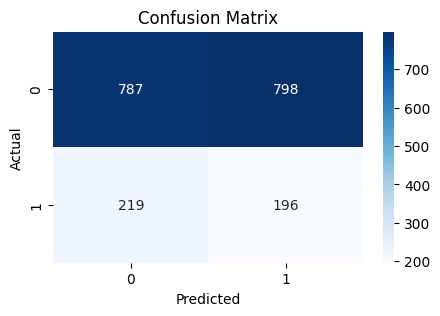

In [ ]:
# Confusion_matrix:
conf_matrix = confusion_matrix(y_test, pred)
print("Confusion Matrix:")
print(conf_matrix)
plt.figure(figsize=(5,3))
sns.heatmap(conf_matrix,annot=True,fmt='g', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
#Classification Report:
print("Classification Report:")
print(classification_report(y_test, pred, zero_division=1))

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.50      0.61      1585
           1       0.20      0.47      0.28       415

    accuracy                           0.49      2000
   macro avg       0.49      0.48      0.44      2000
weighted avg       0.66      0.49      0.54      2000

